<a href="https://colab.research.google.com/github/asritha6863-wq/ERP-frontend/blob/main/UAE_SCM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q "rembg[gpu]" pymatting pillow opencv-python-headless scipy onnxruntime-gpu
print("Install complete")

Install complete


In [2]:
import io, os, zipfile, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter
from scipy import ndimage as ndi
from rembg import remove, new_session
from pymatting import estimate_foreground_ml
from google.colab import files

W, H, BG_HEX, SCALE = 1080, 1350, "#C2185B", 0.88
MAX_SIDE, PAD_RATIO = 3000, 0.05
MODEL = "birefnet-general"      # or "isnet-general-use" (faster)
ERODE_PX, BLUR_PX = 3, 0.7
OUT = "/content/jewellery_output"; os.makedirs(OUT, exist_ok=True)
rgb_bg = tuple(int(BG_HEX[i:i+2], 16) for i in (1, 3, 5))

def show(imgs, titles, cmap=None, size=5):
    fig, ax = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size * 1.2))
    ax = np.atleast_1d(ax)
    for a, im, t in zip(ax, imgs, titles):
        a.imshow(im, cmap=cmap); a.set_title(t); a.axis("off")
    plt.show()

print("Settings ready | Canvas:", W, "x", H, "| Background:", BG_HEX, rgb_bg)

Settings ready | Canvas: 1080 x 1350 | Background: #C2185B (194, 24, 91)


In [3]:
t = time.time()
session = new_session(MODEL)
print(f"Model loaded: {MODEL} ({time.time()-t:.1f}s)")

Model loaded: birefnet-general (18.1s)


/usr/local/lib/python3.13/dist-packages/rembg/session_factory.py:56: RuntimeWarning: CUDAExecutionProvider was requested but the session is running on CPU. onnxruntime could not load the provider, usually because the matching CUDA/cuDNN runtime libraries are missing or are a different major version than the onnxruntime-gpu build. Inference will be slow. See the onnxruntime stderr output above for the specific library that failed to load.
  return session_class(model_name, sess_opts, *args, **kwargs)


In [4]:
uploaded = files.upload()
fname, data = next(iter(uploaded.items()))
print("Using:", fname, "| size:", round(len(data)/1024), "KB")

Saving images (1).jpeg to images (1) (3).jpeg
Using: images (1) (3).jpeg | size: 25 KB


Before: mode RGB | size (554, 554)
After : mode RGB | size (554, 554)


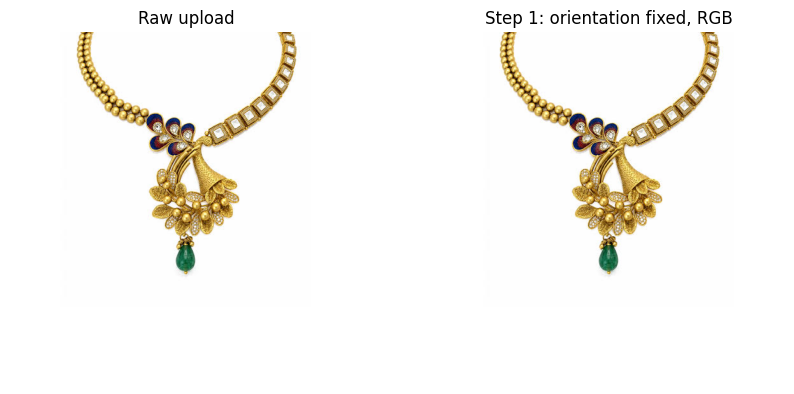

In [5]:
raw = Image.open(io.BytesIO(data))
print("Before: mode", raw.mode, "| size", raw.size)
img = ImageOps.exif_transpose(raw).convert("RGB")
print("After : mode", img.mode, "| size", img.size)
show([raw, img], ["Raw upload", "Step 1: orientation fixed, RGB"])

In [6]:
before = img.size
if max(img.size) > MAX_SIDE:
    img.thumbnail((MAX_SIDE, MAX_SIDE), Image.LANCZOS)
    print(f"Downscaled: {before} -> {img.size}")
else:
    print(f"No resize needed: {img.size}")
print("Megapixels:", round(img.width * img.height / 1e6, 2))

No resize needed: (554, 554)
Megapixels: 0.31


Average pixel change in the AI copy: 2.54 (0-255 scale)


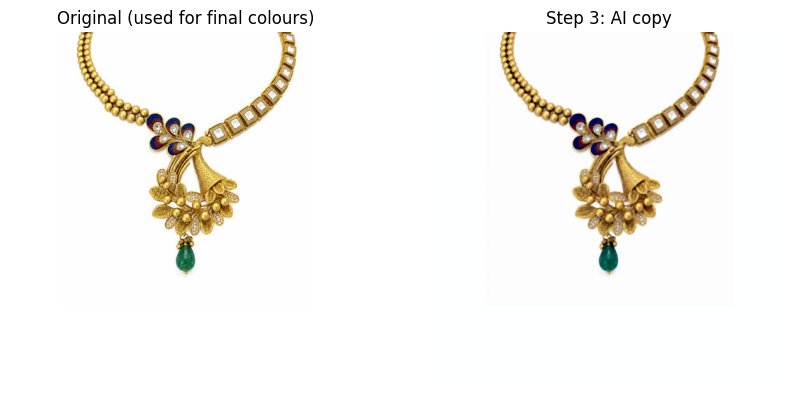

In [7]:
contrast = ImageOps.autocontrast(img, cutoff=0.5)
arr = np.asarray(contrast)
# Apply median filter along spatial dimensions (axes 0 and 1), keeping channels separate
filtered_arr = ndi.median_filter(arr, size=(3, 3, 1))
prep = Image.fromarray(filtered_arr)

diff = np.abs(np.asarray(img).astype(int) - np.asarray(prep).astype(int)).mean()
print("Average pixel change in the AI copy:", round(diff, 2), "(0-255 scale)")
show([img, prep], ["Original (used for final colours)", "Step 3: AI copy"])

Border fill colour: (254, 255, 255) | pad: 27 px
Size: (554, 554) -> (608, 608)
Mask time: 72.4s | Product coverage: 8.8%
Position: x=65, y=150 | Margins: L/R 65px, T/B 150px


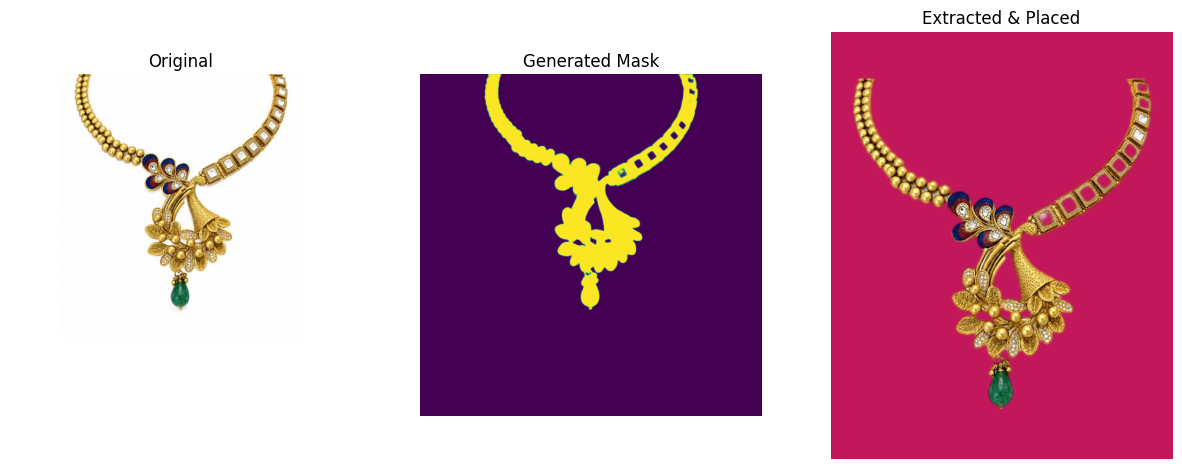

In [8]:
# Step 4: Add padding to preparation copy
arr = np.asarray(prep)
border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
fill = tuple(int(v) for v in np.median(border, axis=0))
pad = int(max(prep.size) * PAD_RATIO)
prep_padded = ImageOps.expand(prep, border=pad, fill=fill)
print("Border fill colour:", fill, "| pad:", pad, "px")
print("Size:", prep.size, "->", prep_padded.size)

# Step 5: Run AI background removal session to get raw mask
t = time.time()
buf = io.BytesIO(); prep_padded.save(buf, "PNG")
m = Image.open(io.BytesIO(remove(
    buf.getvalue(), session=session, only_mask=True,
    alpha_matting=True,
    alpha_matting_foreground_threshold=240,
    alpha_matting_background_threshold=10,
    alpha_matting_erode_size=5))).convert("L")
raw_mask = m.crop((pad, pad, pad + img.width, pad + img.height))
b = np.asarray(raw_mask) > 127
print(f"Mask time: {time.time()-t:.1f}s | Product coverage: {b.mean()*100:.1f}%")

# Step 6: Clean mask (erode/blur)
mask = raw_mask
if ERODE_PX >= 3:
    mask = Image.fromarray(ndi.minimum_filter(np.asarray(mask), size=ERODE_PX))
if BLUR_PX > 0:
    mask = mask.filter(ImageFilter.GaussianBlur(radius=BLUR_PX))

# Step 7: Apply mask and remove halo
m_arr = np.asarray(mask) / 255.0
fg = estimate_foreground_ml(np.asarray(img) / 255.0, m_arr)
fg_img = Image.fromarray((fg * 255).astype("uint8")).convert("RGBA"); fg_img.putalpha(mask)

# Step 8: Crop, resize and sharpen foreground object
bbox = mask.point(lambda p: 255 if p > 8 else 0).getbbox()
assert bbox, "Product not detected"
product = fg_img.crop(bbox)

tw, th = int(W * SCALE), int(H * SCALE)
ratio = min(tw / product.width, th / product.height)
product = product.resize((max(1, round(product.width * ratio)),
                          max(1, round(product.height * ratio))), Image.LANCZOS)

r_, g_, b_, a_ = product.split()
rgb_sharp = Image.merge("RGB", (r_, g_, b_)).filter(
    ImageFilter.UnsharpMask(radius=1, percent=60, threshold=2))
product_sharp = Image.merge("RGBA", (*rgb_sharp.split(), a_))

# Step 9: Composite onto target colored canvas and save
canvas = Image.new("RGBA", (W, H), rgb_bg + (255,))
x, y = (W - product_sharp.width)//2, (H - product_sharp.height)//2
canvas.alpha_composite(product_sharp, (x, y))
print(f"Position: x={x}, y={y} | Margins: L/R {x}px, T/B {y}px")

name = os.path.splitext(fname)[0]
canvas.save(f"{OUT}/{name}.png")
canvas.convert("RGB").save(f"{OUT}/{name}.jpg", quality=98, subsampling=0, optimize=True)

show([img, raw_mask, canvas], ["Original", "Generated Mask", "Extracted & Placed"], size=5)

Isolated foreground saved to: /content/jewellery_output/images (1) (3)_foreground.png


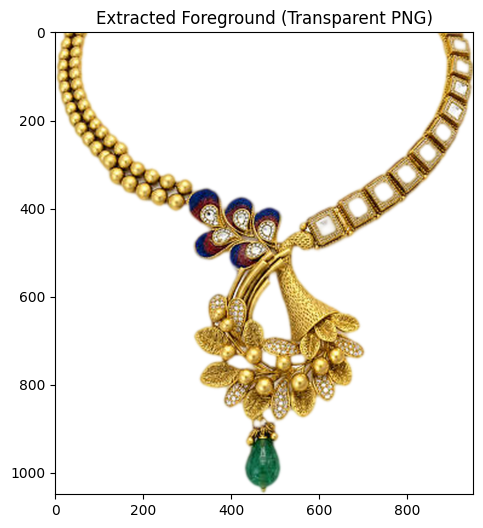

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# Save and display the standalone extracted foreground object with a transparent background
fg_transparent_path = f"{OUT}/{name}_foreground.png"
product_sharp.save(fg_transparent_path)
print(f"Isolated foreground saved to: {fg_transparent_path}")

# Display the transparent foreground against a grid/gray backdrop to show transparency
plt.figure(figsize=(6, 6))
plt.imshow(product_sharp)
plt.title("Extracted Foreground (Transparent PNG)")
plt.axis("on") # keeping axes to show bounds
plt.show()

# Automatically trigger a browser download for the transparent PNG
files.download(fg_transparent_path)

Border fill colour: (254, 255, 255) | pad: 27 px
Size: (554, 554) -> (608, 608)


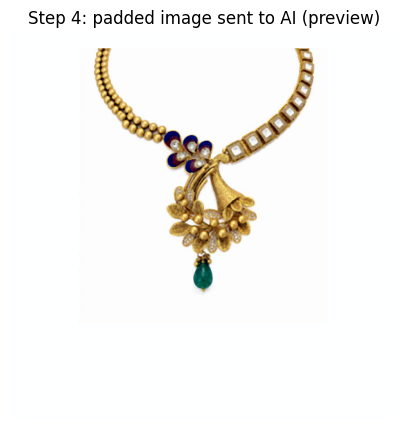

2513

In [10]:
import gc

# free memory from earlier steps
for v in ("raw", "before", "after", "orig_rgba", "green"):
    if v in globals(): del globals()[v]
gc.collect()

arr = np.asarray(prep)
border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
fill = np.median(border, axis=0).astype("uint8")
pad = int(max(prep.size) * PAD_RATIO)

padded = np.empty((arr.shape[0] + 2*pad, arr.shape[1] + 2*pad, 3), dtype="uint8")
padded[:] = fill                                   # fill with border colour
padded[pad:pad + arr.shape[0], pad:pad + arr.shape[1]] = arr
prep_padded = Image.fromarray(padded)

print("Border fill colour:", tuple(int(v) for v in fill), "| pad:", pad, "px")
print("Size:", prep.size, "->", prep_padded.size)

# show a small preview only (not full size)
preview = prep_padded.copy(); preview.thumbnail((800, 800))
show([preview], ["Step 4: padded image sent to AI (preview)"])
del preview, arr, padded; gc.collect()

Mask pixels: 27141 -> 24113 (-11.16% change)


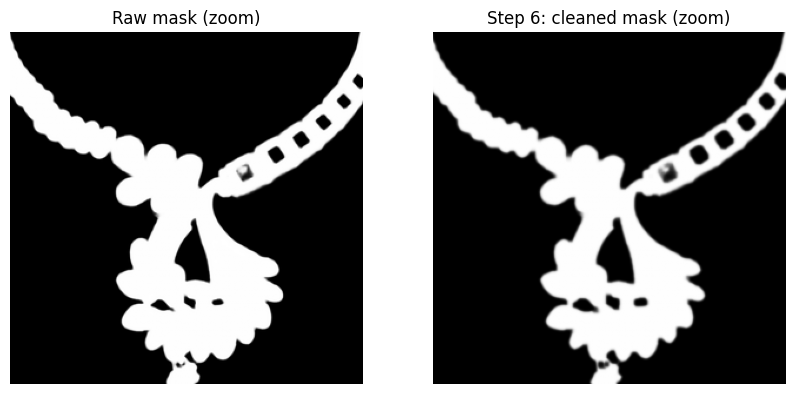

In [11]:
mask = raw_mask
if ERODE_PX >= 3:
    mask = Image.fromarray(ndi.minimum_filter(np.asarray(mask), size=ERODE_PX))
if BLUR_PX > 0:
    mask = mask.filter(ImageFilter.GaussianBlur(radius=BLUR_PX))

a0, a1 = (np.asarray(raw_mask) > 127).sum(), (np.asarray(mask) > 127).sum()
print(f"Mask pixels: {a0} -> {a1} ({(a1-a0)/a0*100:.2f}% change)")

ys, xs = np.where(np.asarray(mask) > 127)
cy, cx = int(ys.mean()), int(xs.mean()); r = 150
crop = (max(0, cx-r), max(0, cy-r), min(img.width, cx+r), min(img.height, cy+r))
show([raw_mask.crop(crop), mask.crop(crop)], ["Raw mask (zoom)", "Step 6: cleaned mask (zoom)"], cmap="gray")

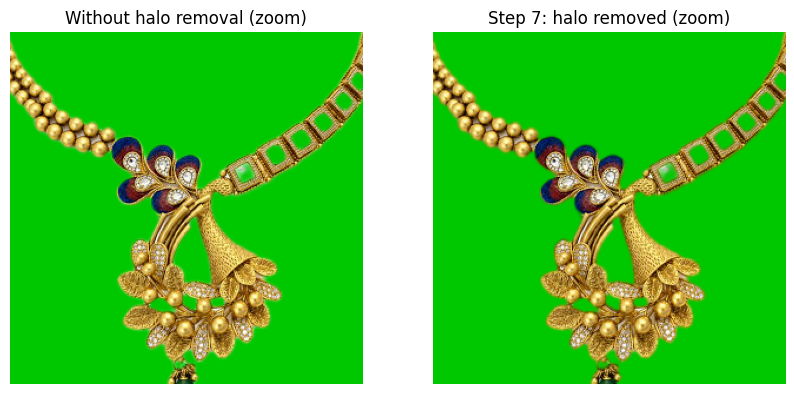

In [12]:
m_arr = np.asarray(mask) / 255.0
fg = estimate_foreground_ml(np.asarray(img) / 255.0, m_arr)
fg_img = Image.fromarray((fg * 255).astype("uint8")).convert("RGBA"); fg_img.putalpha(mask)

orig_rgba = img.convert("RGBA"); orig_rgba.putalpha(mask)
green = Image.new("RGBA", img.size, (0, 200, 0, 255))
before = green.copy(); before.alpha_composite(orig_rgba)
after  = green.copy(); after.alpha_composite(fg_img)
show([before.crop(crop), after.crop(crop)], ["Without halo removal (zoom)", "Step 7: halo removed (zoom)"])

Cropped size: (346, 382) | bbox: (104, 0, 450, 382)
Resized to: (950, 1049)


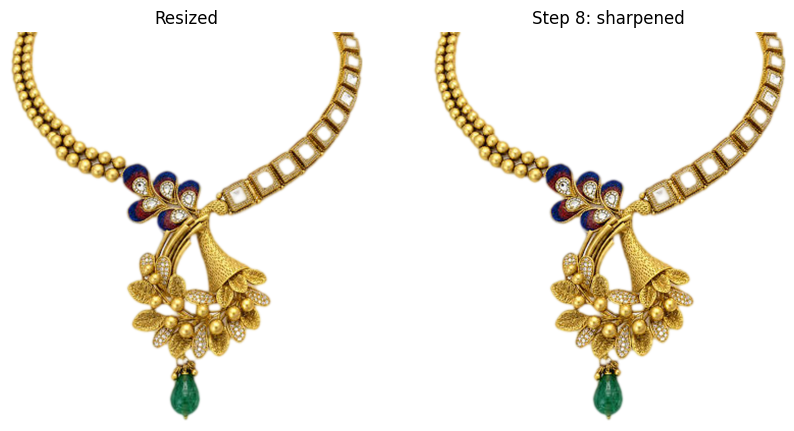

In [13]:
bbox = mask.point(lambda p: 255 if p > 8 else 0).getbbox()
assert bbox, "Product not detected"
product = fg_img.crop(bbox)
print("Cropped size:", product.size, "| bbox:", bbox)

tw, th = int(W * SCALE), int(H * SCALE)
ratio = min(tw / product.width, th / product.height)
# ratio = min(ratio, 1)   # uncomment to NEVER enlarge small crops
product = product.resize((max(1, round(product.width * ratio)),
                          max(1, round(product.height * ratio))), Image.LANCZOS)
print("Resized to:", product.size)

r_, g_, b_, a_ = product.split()
rgb_sharp = Image.merge("RGB", (r_, g_, b_)).filter(
    ImageFilter.UnsharpMask(radius=1, percent=60, threshold=2))
product_sharp = Image.merge("RGBA", (*rgb_sharp.split(), a_))
show([product, product_sharp], ["Resized", "Step 8: sharpened"])

Position: x=65, y=150 | Margins: L/R 65px, T/B 150px
Saved: /content/jewellery_output/images (1) (3).png | 528 KB
Saved: /content/jewellery_output/images (1) (3).jpg | 230 KB


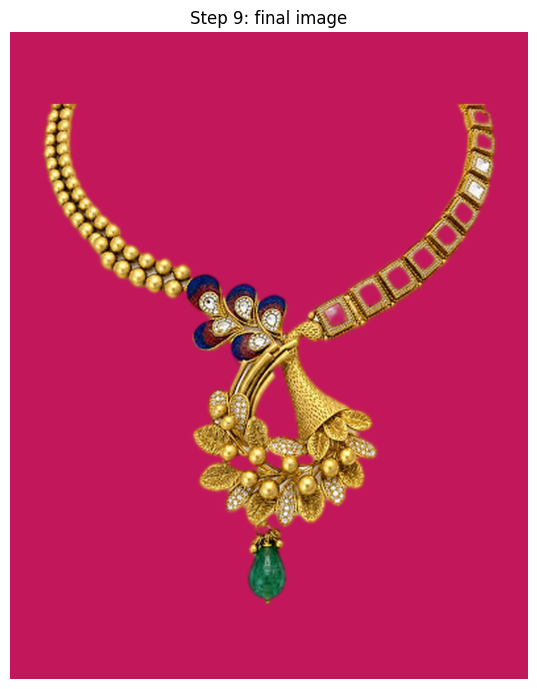

In [14]:
canvas = Image.new("RGBA", (W, H), rgb_bg + (255,))
x, y = (W - product_sharp.width)//2, (H - product_sharp.height)//2
canvas.alpha_composite(product_sharp, (x, y))
print(f"Position: x={x}, y={y} | Margins: L/R {x}px, T/B {y}px")

name = os.path.splitext(fname)[0]
canvas.save(f"{OUT}/{name}.png")
canvas.convert("RGB").save(f"{OUT}/{name}.jpg", quality=98, subsampling=0, optimize=True)
for ext in ("png", "jpg"):
    p = f"{OUT}/{name}.{ext}"; print("Saved:", p, "|", round(os.path.getsize(p)/1024), "KB")
show([canvas], ["Step 9: final image"], size=7)

In [15]:
def quality_report(img, mask):
    m = np.asarray(mask) / 255.0; b = m > 0.5; rgb = np.asarray(img).astype(float); r = {}
    r["Coverage %"] = round(b.mean() * 100, 1)
    lab, n = ndi.label(b)
    areas = ndi.sum(b, lab, range(1, n + 1)) if n else []
    r["Pieces (>0.1% area)"] = int(sum(a > b.size * 0.001 for a in areas))
    lab_bg, nbg = ndi.label(~b)
    edge = set(np.unique(np.concatenate([lab_bg[0], lab_bg[-1], lab_bg[:, 0], lab_bg[:, -1]])))
    r["Holes detected"] = int(sum(1 for i in range(1, nbg + 1) if i not in edge and (lab_bg == i).sum() > 50))
    soft = (m > 0.04) & (m < 0.96)
    r["Uncertain edge pixels %"] = round(soft.sum() / max(1, (m > 0.04).sum()) * 100, 2)
    bgcol = np.median(rgb[m < 0.02], axis=0) if (m < 0.02).any() else np.array([255, 255, 255])
    ring = b & ~ndi.binary_erosion(b, iterations=2)
    d = np.linalg.norm(rgb[ring] - bgcol, axis=1) if ring.any() else np.array([999])
    r["Halo risk %"] = round((d < 30).mean() * 100, 1)
    s = 100 - min(30, r["Halo risk %"] * 0.6) - min(25, r["Uncertain edge pixels %"] * 1.5) - (10 if r["Pieces (>0.1% area)"] > 1 else 0)
    r["Quality score /100"] = round(max(s, 0), 1)
    return r

rep = quality_report(img, mask)
targets = {"Coverage %": "-", "Pieces (>0.1% area)": "1 (or real count)", "Holes detected": "= real holes",
           "Uncertain edge pixels %": "< 5", "Halo risk %": "< 10", "Quality score /100": ">= 85"}
print(f"{'Metric':28} {'Value':>8}   Target")
for k, v in rep.items(): print(f"{k:28} {v:>8}   {targets[k]}")

Metric                          Value   Target
Coverage %                        7.9   -
Pieces (>0.1% area)                 1   1 (or real count)
Holes detected                     12   = real holes
Uncertain edge pixels %         27.85   < 5
Halo risk %                       0.2   < 10
Quality score /100               74.9   >= 85
